In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


Data Cleaning

In [14]:
df = pd.read_csv("dataAnalystJobsIndia_7th_July_2024.csv")

print(df.shape)
display(df.head())

(1561, 16)


,Unnamed: 0,job_title,company,experience,min exp,max exp,salary,base salary,max salary,location,jobListed(days ago),postedIn,rating,reviews count,details,salary data provide by
0,0,JP Morgan Chase - Client Data Analyst (4-8 yrs),JP Morgan Chase,4-8 Yrs,4.0,8.0,NaN,NaN,NaN,Hyderabad / Secunderabad,3.0,iimjobs,4.1,5300.0,"Banking, KYC, Banking Operations",NaN
1,1,Data Analyst - Bangalore,Schneider Electric,5-10 Yrs,5.0,10.0,₹ 8 - 16L/yr,800000.0,1600000.0,"Bangalore / Bengaluru, Bangalore Rural",4.0,Naukri,4.2,3500.0,"ERP, SAP, Data Analysis",Salary Listed by Company
2,2,Senior IT ATLAS Data Analyst and Integration S...,SAP Labs India Pvt. Ltd.,7-11 Yrs,7.0,11.0,NaN,NaN,NaN,Bangalore / Bengaluru,7.0,Naukri,4.3,1500.0,"data quality, Data analysis, quality management",NaN
3,3,Consultant Data Analyst,Pfizer,2-6 Yrs,2.0,6.0,NaN,NaN,NaN,Mumbai,3.0,Naukri,4.1,1700.0,"Power Bi, Commercial Operations, Data Management",NaN
4,4,Senior Data Analyst - Retail Liabilities,IDFC FIRST Bank,5-10 Yrs,5.0,10.0,NaN,NaN,NaN,Mumbai,5.0,Naukri,4.5,2300.0,"Test strategy, Analytical, Manager Technology",NaN


In [4]:
# Remove duplicates
df.drop_duplicates(inplace=True)

# Remove unnecessary column
df.drop(columns=['Unnamed: 0'], errors='ignore', inplace=True)

# Clean text columns
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip().replace('', np.nan)

# Convert numeric columns
for col in ['min exp', 'max exp', 'base salary',
            'max salary', 'rating', 'reviews count']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Extract salary values if salary information exists
def get_salary(value):
    numbers = re.findall(r'\d+(?:\.\d+)?', str(value))
    if len(numbers) >= 2:
        return float(numbers[0]) * 100000, float(numbers[1]) * 100000
    return (float(numbers[0]) * 100000, np.nan) if numbers else (np.nan, np.nan)

if 'salary' in df.columns:
    salaries = df['salary'].apply(get_salary)

    if 'base salary' not in df.columns:
        df['base salary'] = np.nan
    if 'max salary' not in df.columns:
        df['max salary'] = np.nan

    df['base salary'] = df['base salary'].fillna(salaries.apply(lambda x: x[0]))
    df['max salary'] = df['max salary'].fillna(salaries.apply(lambda x: x[1]))

# Check the cleaned data
print("Dataset shape:", df.shape)
print("\nMissing values:")
display(df.isnull().sum())

display(df.head())

Dataset shape: (1561, 15)

Missing values:


job_title                    0
company                      0
experience                  34
min exp                     34
max exp                     34
salary                    1218
base salary               1218
max salary                1218
location                    33
jobListed(days ago)          0
postedIn                     0
rating                     437
reviews count              437
details                     33
salary data provide by    1218
dtype: int64

,job_title,company,experience,min exp,max exp,salary,base salary,max salary,location,jobListed(days ago),postedIn,rating,reviews count,details,salary data provide by
0,JP Morgan Chase - Client Data Analyst (4-8 yrs),JP Morgan Chase,4-8 Yrs,4.0,8.0,NaN,NaN,NaN,Hyderabad / Secunderabad,3.0,iimjobs,4.1,5300.0,"Banking, KYC, Banking Operations",NaN
1,Data Analyst - Bangalore,Schneider Electric,5-10 Yrs,5.0,10.0,₹ 8 - 16L/yr,800000.0,1600000.0,"Bangalore / Bengaluru, Bangalore Rural",4.0,Naukri,4.2,3500.0,"ERP, SAP, Data Analysis",Salary Listed by Company
2,Senior IT ATLAS Data Analyst and Integration S...,SAP Labs India Pvt. Ltd.,7-11 Yrs,7.0,11.0,NaN,NaN,NaN,Bangalore / Bengaluru,7.0,Naukri,4.3,1500.0,"data quality, Data analysis, quality management",NaN
3,Consultant Data Analyst,Pfizer,2-6 Yrs,2.0,6.0,NaN,NaN,NaN,Mumbai,3.0,Naukri,4.1,1700.0,"Power Bi, Commercial Operations, Data Management",NaN
4,Senior Data Analyst - Retail Liabilities,IDFC FIRST Bank,5-10 Yrs,5.0,10.0,NaN,NaN,NaN,Mumbai,5.0,Naukri,4.5,2300.0,"Test strategy, Analytical, Manager Technology",NaN


Exploratory data analysis (EDA)

Job Listings by Portal

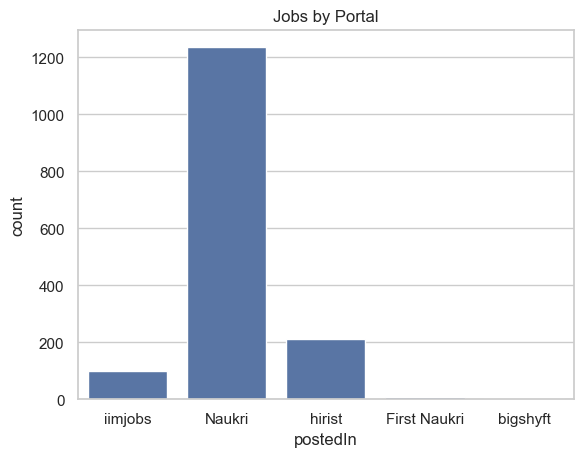

In [5]:
sns.set_theme(style="whitegrid")

sns.countplot(data=df, x='postedIn')
plt.title("Jobs by Portal")
plt.show()

Top 10 Locations

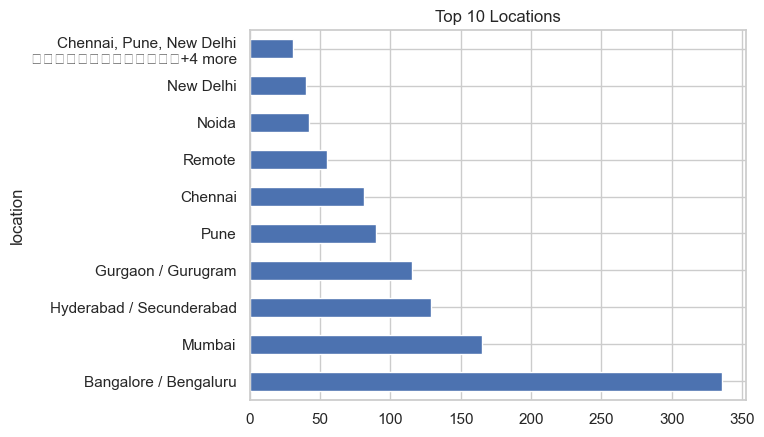

In [6]:
df['location'].value_counts().head(10).plot(
    kind='barh',
    title="Top 10 Locations"
)
plt.show()

Top 10 Companies

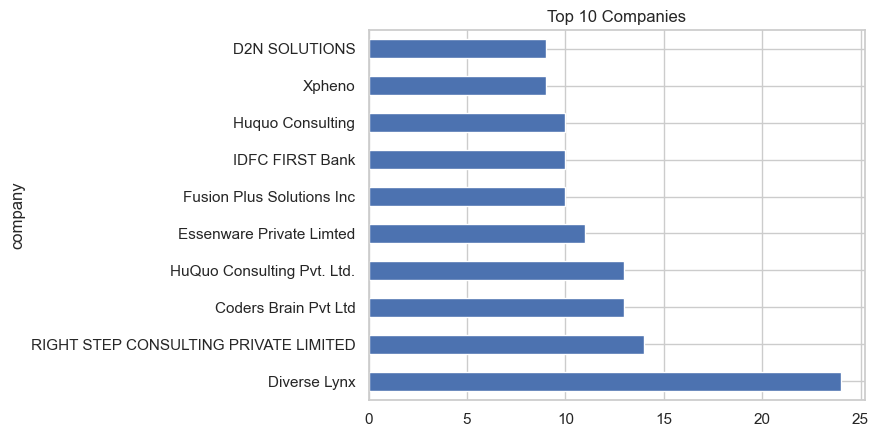

In [7]:
df['company'].value_counts().head(10).plot(
    kind='barh',
    title="Top 10 Companies"
)
plt.show()

Experience Distribution

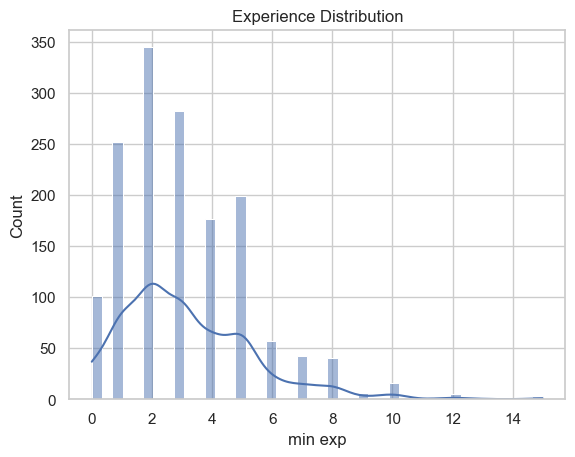

In [8]:
sns.histplot(df['min exp'].dropna(), kde=True)
plt.title("Experience Distribution")
plt.show()

Ratings Distribution

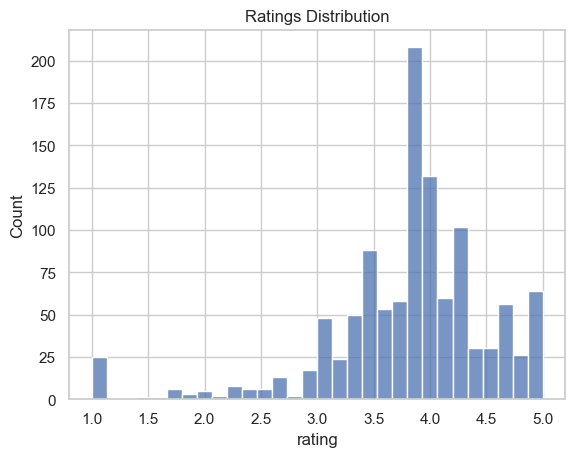

In [9]:
sns.histplot(df['rating'].dropna())
plt.title("Ratings Distribution")
plt.show()

Reviews Count Distribution

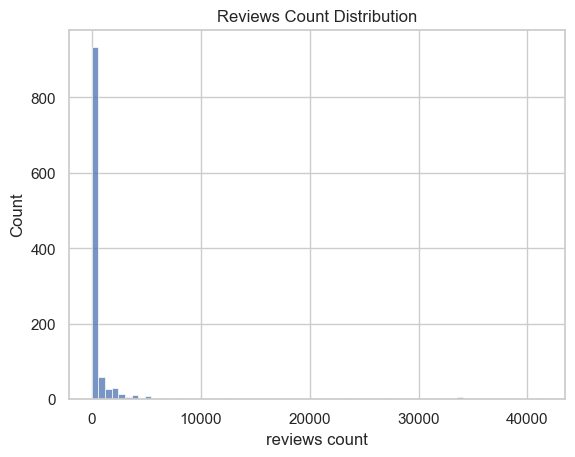

In [10]:
sns.histplot(df['reviews count'].dropna())
plt.title("Reviews Count Distribution")
plt.show()

Average Rating by Portal

In [11]:
display(df.groupby('postedIn')['rating'].mean())

postedIn
First Naukri    4.066667
Naukri          3.817819
bigshyft        3.725000
hirist          3.675294
iimjobs         3.836364
Name: rating, dtype: float64

Jobs by Experience Level

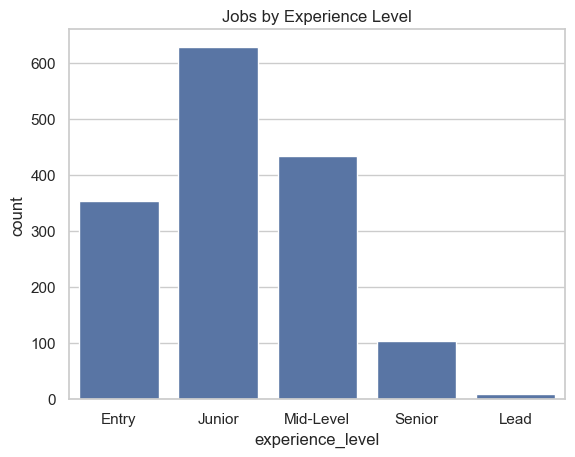

In [12]:
df['experience_level'] = pd.cut(
    df['min exp'],
    [-1, 1, 3, 6, 10, np.inf],
    labels=['Entry', 'Junior', 'Mid-Level', 'Senior', 'Lead']
)

sns.countplot(data=df, x='experience_level')
plt.title("Jobs by Experience Level")
plt.show()

Statistical analysis

calculate both Portal reating

In [15]:
naukri = df.loc[df['postedIn'] == 'Naukri', 'rating'].dropna()

iimjobs = df.loc[df['postedIn'] == 'iimjobs', 'rating'].dropna()

calculate Average rating 

In [16]:
print("Naukri average rating:", naukri.mean())
print("iimjobs average rating:", iimjobs.mean())

Naukri average rating: 3.8178194607268465
iimjobs average rating: 3.8363636363636364


T-test

In [18]:
from scipy import stats
t_stat, p_value = stats.ttest_ind(
    naukri, iimjobs, equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: -0.25855662727012513
P-value: 0.7964531516950539


Final conclusion

In [19]:
if p_value < 0.05:
    print("Reject H0: Ratings differ significantly.")
else:
    print("Fail to reject H0: No significant difference found.")

Fail to reject H0: No significant difference found.


Correlation between ratings and reviews

Pearson correlation: 0.01881021466134565
Pearson p-value: 0.5287028533719214
Spearman correlation: -0.06164236812126421
Spearman p-value: 0.03880068180188762


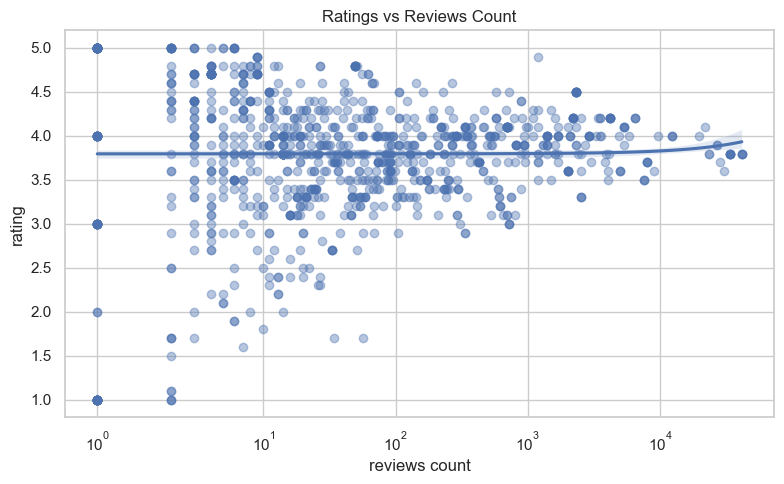

In [20]:
corr_data = df[['rating', 'reviews count']].dropna()

# Pearson correlation
pearson_r, pearson_p = stats.pearsonr(
    corr_data['rating'], corr_data['reviews count']
)

# Spearman correlation
spearman_r, spearman_p = stats.spearmanr(
    corr_data['rating'], corr_data['reviews count']
)

print("Pearson correlation:", pearson_r)
print("Pearson p-value:", pearson_p)

print("Spearman correlation:", spearman_r)
print("Spearman p-value:", spearman_p)

plt.figure(figsize=(8, 5))
sns.regplot(
    data=corr_data,
    x='reviews count',
    y='rating',
    scatter_kws={'alpha': 0.4}
)
plt.xscale('symlog')
plt.title('Ratings vs Reviews Count')
plt.tight_layout()
plt.show()

Machine Learning: Base Salary Prediction

Prepare the Dataset

In [21]:
model_df = df.loc[
    df['base salary'].notna() &
    (df['base salary'] > 0)
].copy()

features = [
    'job_title', 'company', 'experience',
    'min exp', 'max exp', 'location',
    'jobListed(days ago)', 'postedIn', 'details'
]

features = [
    col for col in features
    if col in model_df.columns
]

X = model_df[features]
y = model_df['base salary']

print("Dataset prepared successfully!")
print("Total records:", len(model_df))
print("Features:", features)

Dataset prepared successfully!
Total records: 343
Features: ['job_title', 'company', 'experience', 'min exp', 'max exp', 'location', 'jobListed(days ago)', 'postedIn', 'details']


Identify Column Types

In [22]:
categorical_cols = X.select_dtypes(
    include=['object', 'string', 'category']
).columns.tolist()

numeric_cols = X.select_dtypes(
    include=[np.number]
).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numeric_cols)

Categorical columns: ['job_title', 'company', 'experience', 'location', 'postedIn', 'details']
Numerical columns: ['min exp', 'max exp', 'jobListed(days ago)']


Create Preprocessing Pipelines

In [25]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        min_frequency=2
    ))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_cols),
    ('categorical', categorical_pipeline, categorical_cols)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


Build the Random Forest Model

In [28]:
from sklearn.ensemble import RandomForestRegressor
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest model created successfully!")

Random Forest model created successfully!


Split Data and Train the Model

In [30]:
from sklearn.model_selection import train_test_split

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Model trained successfully!
Training records: 274
Testing records: 69


Predict Base Salaries

In [32]:
predictions = model.predict(X_test)

print("Salary predictions generated successfully!")

Salary predictions generated successfully!


Evaluate Model Performance

In [34]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [35]:
mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

r2 = r2_score(y_test, predictions)

print("BASE SALARY PREDICTION — MODEL PERFORMANCE")
print("-" * 45)
print(f"Mean Absolute Error     : {mae:,.2f}")
print(f"Root Mean Squared Error : {rmse:,.2f}")
print(f"R-squared Score         : {r2:.3f}")

BASE SALARY PREDICTION — MODEL PERFORMANCE
---------------------------------------------
Mean Absolute Error     : 352,595.94
Root Mean Squared Error : 468,575.96
R-squared Score         : 0.100


Compare Actual vs Predicted Salaries

In [36]:
results = pd.DataFrame({
    'Actual Salary': y_test,
    'Predicted Salary': predictions
})

results['Prediction Error'] = (
    results['Actual Salary'] -
    results['Predicted Salary']
)

display(results.head(10).round(2))

,Actual Salary,Predicted Salary,Prediction Error
1189,100000.0,623874.38,-523874.38
754,1300000.0,452406.61,847593.39
720,600000.0,321156.17,278843.83
177,200000.0,378836.87,-178836.87
890,1300000.0,1599737.06,-299737.06
1418,1160000.0,323342.15,836657.85
1039,60000.0,720139.87,-660139.87
1033,200000.0,1157024.59,-957024.59
1529,500000.0,412125.59,87874.41
107,700000.0,209020.01,490979.99


Feature selection using permutation importance

Calculate Feature Importance

In [37]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': importance.importances_mean
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

display(feature_importance.round(4))

,Feature,Importance
0,jobListed(days ago),35497.7812
1,min exp,24924.8431
2,max exp,15147.3017
3,company,11832.7372
4,experience,5665.0769
5,job_title,3242.9089
6,location,2646.0327
7,postedIn,818.2749
8,details,36.9204


Visualize Important Features

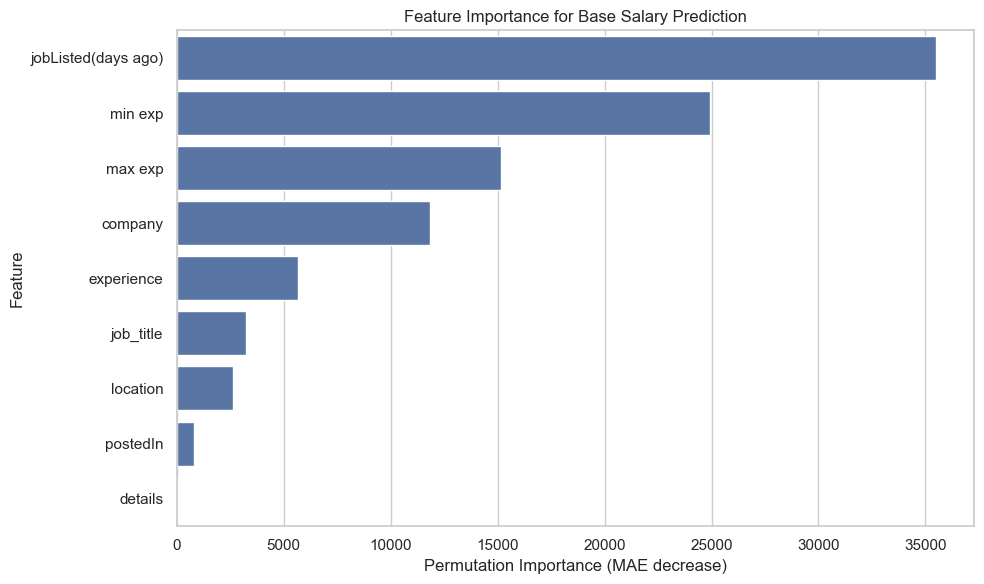

In [39]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance for Base Salary Prediction')
plt.xlabel('Permutation Importance (MAE decrease)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

Save Results for Your Project

In [40]:
feature_importance.to_csv(
    'base_salary_feature_importance.csv',
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


Save cleaned dataset

In [41]:
df.to_csv('cleaned_data_analyst_jobs_india.csv', index=False)

Save feature importance results

In [42]:
feature_importance.to_csv(
    'salary_model_feature_importance.csv',
    index=False
)

for Location check

In [43]:
import os
print(os.getcwd())

C:\Users\Admin
